# Tópicos por período legal

Este notebook responde: **sobre o que falam os anúncios, e isso muda ao longo do século XIX?**
Usamos o modelo de tópicos `t3` (6 tópicos, corpus `corp2`, campos `c4`), já gravado no banco compartilhado do grupo.
O modelo `t2` (8 tópicos) aparece só na seção 8, para comparação.

Cada gráfico vem com uma ou duas frases dizendo o que ele mostra. Os números dessas frases foram lidos da saída
da própria execução; se o banco mudar, **confira os números de novo**.

> **Cuidado ao ler:** os anúncios foram achados por **frases de busca**, não por sorteio. O que aparece aqui descreve
> o que a busca encontrou, não todos os anúncios do século XIX. Os **nomes** dos tópicos são **hipóteses do grupo**, não fatos.

## 1. O que é um tópico e por que k = 6
**Um tópico é um grupo de palavras que costumam aparecer juntas nos mesmos anúncios.** O programa (LDA) não lê o sentido:
ele só agrupa palavras. Quem dá nome ao grupo somos nós, olhando as palavras e os anúncios.

**Por que 6 tópicos (k = 6)?** Rodamos o modelo várias vezes com sementes diferentes (ver `scripts/estabilidade_topicos.py`)
e medimos quantos tópicos **se repetem** (similaridade de cosseno ≥ 0,8). Com k = 6, 52% dos tópicos se repetem;
com k = 8, 43%; com k = 12, 21%. Quanto mais tópicos, menos estáveis. Mesmo em k = 8, quatro temas se repetem em todas as
sementes: aluguel de trabalho doméstico (0,87), fuga (0,86), fuga descrita (0,84) e ama de leite (0,79).
Ou seja, a estabilidade é **moderada**: os resultados abaixo são pistas, não medidas exatas.

## Preparação: ler o banco
O banco devolve no máximo 1000 linhas por consulta, então lemos em blocos (paginação).

In [1]:
import sys
from pathlib import Path

RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from hdb import config
from hdb.banco import BancoSupabase

pd.set_option("display.max_colwidth", 200)
pd.set_option("display.width", 200)
db = BancoSupabase().cliente      # lê o config/.env pelo módulo hdb

def ler_tudo(consulta, bloco=1000):
    """Executa a consulta em blocos de 1000 linhas e junta o resultado."""
    linhas, inicio = [], 0
    while True:
        parte = consulta().range(inicio, inicio + bloco - 1).execute().data
        linhas += parte
        if len(parte) < bloco:
            return pd.DataFrame(linhas)
        inicio += bloco

MODELO, COMPARA = "t3", "t2"
palavras = ler_tudo(lambda: db.table("topico_palavras").select("versao,topico,palavra,peso")
                    .in_("versao", [MODELO, COMPARA]).order("versao").order("topico").order("peso", desc=True))
dist = ler_tudo(lambda: db.table("anuncio_topicos").select("anuncio_id,topico,proporcao")
                .eq("versao", MODELO).order("anuncio_id").order("topico"))
anuncios = ler_tudo(lambda: db.table("anuncios_completos")
                    .select("id,periodo_legal,c_tipo,c_sexo,c_idade_min,c_idade_max,ano,texto")
                    .eq("versao", config.VERSAO_ANUNCIOS).eq("c_versao", "c4").order("id"))
print(f"{dist['anuncio_id'].nunique()} anúncios no modelo {MODELO}; {len(anuncios)} anúncios com campos c4 no banco")

655 anúncios no modelo t3; 11612 anúncios com campos c4 no banco


In [2]:
PERIODOS = ["antes de 1831", "1831–1850", "1850–1871", "1871–1888"]
def periodo_curto(p):
    return p if p.startswith("antes") else p.split(" ")[0]

# Nomes SUGERIDOS (provisórios): o grupo deve confirmar
NOMES = {0: "Venda de jovens (idade e nação)", 1: "Fuga em geral", 2: "Fuga com descrição do corpo",
         3: "Aluguel de trabalho doméstico", 4: "Venda e ama de leite", 5: "Avisos judiciais e de navegação"}
K = len(NOMES)
rot = lambda t: f"T{t} {NOMES[t]}"

# Uma linha por anúncio do modelo, com o tópico dominante
pivo = dist.pivot(index="anuncio_id", columns="topico", values="proporcao")
base = anuncios.drop_duplicates("id").set_index("id").join(pivo, how="inner")
base["dominante"] = base[list(range(K))].idxmax(axis=1)
base["periodo"] = pd.Categorical(base["periodo_legal"].map(periodo_curto), categories=PERIODOS, ordered=True)
print(len(base), "anúncios na base de análise")

# Paleta Okabe-Ito, uma cor por tópico
CORES = ["#0072B2", "#D55E00", "#E69F00", "#009E73", "#CC79A7", "#999999"]
plt.rcParams.update({"figure.dpi": 110, "font.size": 10, "axes.spines.top": False, "axes.spines.right": False})

655 anúncios na base de análise


## 2. Os 6 tópicos do modelo `t3`
Abaixo, as **12 palavras de maior peso** de cada tópico (as palavras estão sem acento, como no corpus padronizado).
A coluna **Nome sugerido** é uma **proposta provisória**: o grupo precisa confirmar ou trocar.

In [3]:
tab = (palavras[palavras["versao"] == MODELO].groupby("topico")["palavra"].apply(lambda s: ", ".join(s.head(12))))
tabela = pd.DataFrame({"Nome sugerido": [NOMES[t] for t in tab.index], "12 palavras de maior peso": tab.values},
                      index=pd.Index(tab.index, name="Tópico"))
tabela

,Nome sugerido,12 palavras de maior peso
Tópico,,
0,Venda de jovens (idade e nação),"vende, anos, nacao, idade, preta, moleque, meio, informa, ainda, engomar, fora, oficial"
1,Fuga em geral,"dia, nome, escravo, fugiu, corrente, preto, bem, idade, anos, fugido, dentes, olhos"
2,Fuga com descrição do corpo,"dia, fugiu, nome, nacao, corrente, alvicaras, estatura, recebera, queira, camisa, noticia, vestido"
3,Aluguel de trabalho doméstico,"aluga, preta, preto, servico, todo, lava, cozinheiro, engomar, forno, bem, bom, lavar"
4,Venda e ama de leite,"vende, leite, preta, ama, aluga, boa, preto, precisa, anos, bom, servico, lava"
5,Avisos judiciais e de navegação,"escravo, dito, direito, tendo, ter, juiz, janeiro, provincia, embarcacoes, parece, rio, quiser"


**Nomes sugeridos (provisórios).** Dois pontos de atenção: o tópico 0 tem palavras de **idade e nação** (`anos`, `idade`, `nacao`, `moleque`) junto de `vende`, mas **não** há palavra de ofício forte (só `oficial` e `engomar`), então trocamos a proposta inicial "venda de homens com ofício" por **"venda de jovens (idade e nação)"**. Os tópicos 3 e 4 compartilham palavras (`aluga`, `preta`, `lava`, `servico`): a diferença é `leite`/`ama`/`vende` no 4. O tópico 5 mistura `escravo`, `juiz`, `direito` (avisos judiciais) com `embarcacoes`, `provincia`, `rio` (navegação), então é um tópico de **ruído**/avisos, não de anúncios de pessoas.

## 3. Os 3 anúncios mais típicos de cada tópico
São os 3 com **maior proporção** daquele tópico. Mostramos os primeiros 250 caracteres do texto original.
Serve para conferir se o nome sugerido faz sentido.

In [4]:
for t in range(K):
    print(f"=== Tópico {t}: {NOMES[t]} ===")
    top3 = base.sort_values(t, ascending=False).head(3)
    for i, r in top3.iterrows():
        txt = " ".join(str(r["texto"]).split())[:250]
        print(f"  [id {i}, {r['periodo']}, tipo {r['c_tipo']}, proporção {r[t]:.2f}] {txt}")
    print()

=== Tópico 0: Venda de jovens (idade e nação) ===
  [id 6150, 1831–1850, tipo venda, proporção 0.98] VENDE-SE a casa da rua dos Latoeiros n. 45; A gr a pretender dirija-se à rua da Misericordia — DESEJA-SE alugar, para o serviço interno de huma casa de pouca familia, huma mulher parda forra, que saiba coser, engommar e cozinhar bein, Fte seg à rua d
  [id 9665, antes de 1831, tipo fuga, proporção 0.97] Tem-se attribuido geralmente o despreciamens to das notas quasi exclusivamente á eua euperabondancia; e daqui se tem querido concluir, que retirada da circulação a porção que superabun e, o mal cessará, porque o metal ha de vir occupar o seu lugar. K
  [id 6164, 1831–1850, tipo aluguel, proporção 0.97] PRECISA-SE alugar hum preto de meia idade, para o serviço ordinario de huma casa , que seja intelligente, e que seu senhor queira responsabilisarse pela fieldade; quem assim o tiver dirija-se à rua dos Ourives n. 71. — BERNARDO Antonio de Miranda com

=== Tópico 1: Fuga em geral ===
  [id 

**Leitura dos exemplos.** T1 (fuga), T2 (fuga com `Signaes`, roupa, gratificação), T3 (aluguel de preto que engoma/cozinha) e T4 (ama de leite) **combinam com o nome**. **Discordâncias:** (a) T0: os 3 mais típicos são anúncios **misturados** na mesma coluna do jornal (venda de casa, aluguel de mulher forra, um texto sobre notas/moeda, aluguel de preto), então o tópico 0 captura em parte **colunas de classificados com vários anúncios juntos**, não só "venda de jovens"; (b) T1: um dos 3 é um anúncio de banhos medicinais tipado como fuga, sinal de recortes mal segmentados; (c) T3: um dos 3 é **venda** (pescador), mostrando que o tópico segue o **serviço doméstico**, não só o aluguel; (d) T5: os 3 são **ruído** (relato de combate naval, mandado judicial, parte de navegação), confirmando o nome "avisos judiciais e de navegação".

## 4. Peso de cada tópico por período legal
Para cada período, a **proporção média** de cada tópico nos anúncios daquele período (cada coluna soma 100%).

               T0 Venda de jovens (idade e nação)  T1 Fuga em geral  T2 Fuga com descrição do corpo  T3 Aluguel de trabalho doméstico  T4 Venda e ama de leite  T5 Avisos judiciais e de navegação    n
periodo                                                                                                                                                                                                
antes de 1831                                12.7              23.8                            25.8                               7.7                     15.8                                14.3  102
1831–1850                                    21.3               9.6                            12.1                              18.4                     30.4                                 8.1  134
1850–1871                                     8.5              12.5                            11.0                              27.6                     33.7                                 6.7  192


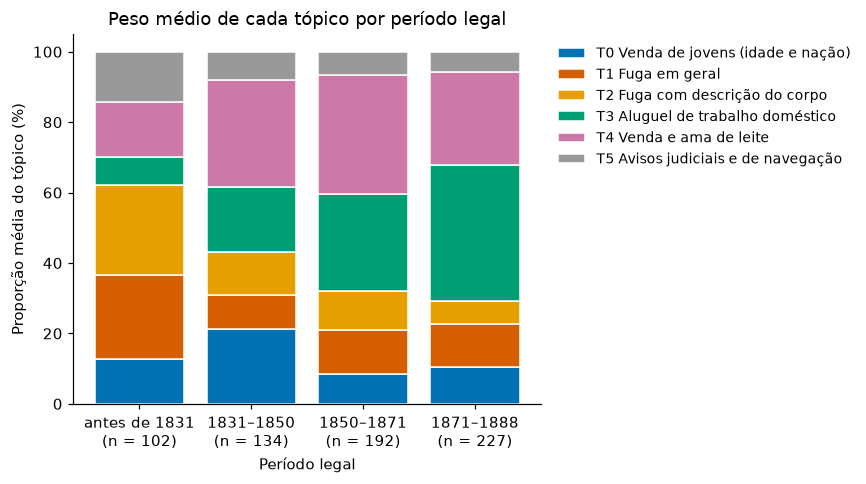

In [5]:
media = base.groupby("periodo", observed=True)[list(range(K))].mean().reindex(PERIODOS)
n_per = base.groupby("periodo", observed=True).size().reindex(PERIODOS)
med = (media * 100).round(1)
med.columns = [rot(t) for t in med.columns]
print(med.assign(n=n_per).to_string())
print("\nComposição por tipo em cada período (% dos anúncios):")
print((pd.crosstab(base["periodo"], base["c_tipo"], normalize="index") * 100).round(1).to_string())

fig, ax = plt.subplots(figsize=(8, 4.5))
fundo = np.zeros(len(PERIODOS))
for t in range(K):
    ax.bar(range(len(PERIODOS)), media[t].values * 100, bottom=fundo, color=CORES[t], edgecolor="white", label=rot(t))
    fundo += media[t].values * 100
ax.set_xticks(range(len(PERIODOS)))
ax.set_xticklabels([f"{p}\n(n = {n_per[p]})" for p in PERIODOS])
ax.set_title("Peso médio de cada tópico por período legal")
ax.set_xlabel("Período legal"); ax.set_ylabel("Proporção média do tópico (%)")
ax.legend(frameon=False, bbox_to_anchor=(1.01, 1), loc="upper left", fontsize=9)
fig.tight_layout(); plt.show()

**O que se vê:** o tópico 3 (aluguel de trabalho doméstico) sobe a cada período, de 7,7% antes de 1831 para 18,4%, 27,6% e 38,6% em 1871–1888. Os tópicos de fuga caem: T2 (fuga com descrição do corpo) vai de 25,8% antes de 1831 para 6,5% em 1871–1888, e T1 (fuga em geral) de 23,8% para 12,2%. O tópico 4 (venda e ama de leite) é o maior em 1831–1850 (30,4%) e 1850–1871 (33,7%). **Cuidado:** a tabela de composição por tipo mostra que a **mistura de tipos muda muito**: anúncios de fuga são 57,8% do corpus antes de 1831 e 18,1% em 1871–1888, enquanto os de aluguel vão de 6,9% para 50,7%. Como o tópico acompanha o tipo (ver seção 7), parte da queda da fuga e da subida do aluguel pode vir de **quantos anúncios de cada tipo a busca achou** em cada período, não de mudança real do que se anunciava.

## 5. Por sexo
Aqui o tópico entra como **proporção média** entre os anúncios de cada sexo (`f` ou `m`).

> **Ressalva:** o sexo vem de **palavras do anúncio** ("preta", "preto", "moleque"…), e o tipo "ama de leite" é feminino
> **por construção**. Por isso, depois do gráfico, cruzamos **tipo × sexo** e **tipo × tópico** para separar o que
> é efeito do tipo.

{'Feminino': 299, 'Masculino': 244}
c_sexo                              Feminino  Masculino
T0 Venda de jovens (idade e nação)      11.6       12.8
T1 Fuga em geral                         7.9       18.1
T2 Fuga com descrição do corpo           7.2       14.2
T3 Aluguel de trabalho doméstico        33.5       23.5
T4 Venda e ama de leite                 34.4       23.4
T5 Avisos judiciais e de navegação       5.4        8.0


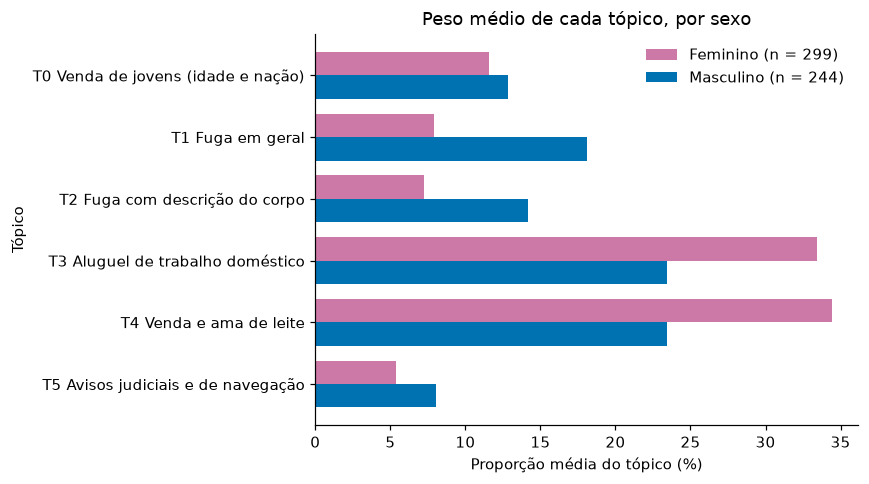

In [6]:
sx = base[base["c_sexo"].isin(["f", "m"])]
n_sx = sx.groupby("c_sexo").size()
m_sx = sx.groupby("c_sexo")[list(range(K))].mean().T * 100
m_sx.index = [rot(t) for t in m_sx.index]
m_sx = m_sx.rename(columns={"f": "Feminino", "m": "Masculino"})
print((n_sx.rename({"f": "Feminino", "m": "Masculino"})).to_dict())
print(m_sx.round(1).to_string())

fig, ax = plt.subplots(figsize=(8, 4.5))
y = np.arange(K); h = 0.38
ax.barh(y - h/2, m_sx["Feminino"].values, h, color="#CC79A7", label=f"Feminino (n = {n_sx.get('f', 0)})")
ax.barh(y + h/2, m_sx["Masculino"].values, h, color="#0072B2", label=f"Masculino (n = {n_sx.get('m', 0)})")
ax.set_yticks(y); ax.set_yticklabels(m_sx.index); ax.invert_yaxis()
ax.set_title("Peso médio de cada tópico, por sexo"); ax.set_xlabel("Proporção média do tópico (%)"); ax.set_ylabel("Tópico")
ax.legend(frameon=False)
fig.tight_layout(); plt.show()

In [7]:
# O sexo é efeito do tipo? Tipo x sexo (contagem) e tipo x tópico médio (%)
print(pd.crosstab(base["c_tipo"], base["c_sexo"].fillna("não diz")).to_string())
print()
por_tipo = base.groupby("c_tipo")[list(range(K))].mean() * 100
por_tipo.columns = [f"T{t}" for t in por_tipo.columns]
print(por_tipo.round(1).assign(n=base.groupby("c_tipo").size()).to_string())
print()
# Dentro de um mesmo tipo, f e m diferem? (fuga e venda são os tipos com os dois sexos)
for tipo in ["fuga", "venda"]:
    s = sx[sx["c_tipo"] == tipo]
    if s["c_sexo"].nunique() == 2:
        d = (s.groupby("c_sexo")[list(range(K))].mean() * 100).round(1)
        d.columns = [f"T{t}" for t in d.columns]
        print(f"Tipo {tipo}: n =", s.groupby("c_sexo").size().to_dict()); print(d.to_string()); print()

c_sexo        ambos    f   m  não diz
c_tipo                               
aluguel          12  130  83        0
ama_de_leite      4   59   2        3
compra            2    4   3        0
fuga              3   27  76       63
venda            22   79  80        3

                T0    T1    T2    T3    T4    T5    n
c_tipo                                               
aluguel        7.7   3.5   4.9  53.1  26.9   3.9  225
ama_de_leite   4.1   2.5   8.6   8.6  67.7   8.5   68
compra        18.4   4.7   6.5  38.1  30.2   2.0    9
fuga           8.5  41.5  31.8   3.1   2.2  12.8  169
venda         24.8   4.7   3.9  21.2  37.2   8.2  184

Tipo fuga: n = {'f': 27, 'm': 76}
          T0    T1    T2   T3   T4    T5
c_sexo                                  
f       14.5  49.2  25.8  4.6  2.3   3.6
m        4.8  48.5  33.8  1.3  1.4  10.1

Tipo venda: n = {'f': 79, 'm': 80}
          T0   T1   T2    T3    T4    T5
c_sexo                                  
f       22.2  5.3  4.0  23.1  39.4   6

**O que se vê:** entre mulheres (n = 299), os tópicos 3 e 4 pesam mais (33,5% e 34,4%); entre homens (n = 244), pesam mais os de fuga, T1 (18,1% contra 7,9%) e T2 (14,2% contra 7,2%). **Mas é efeito do tipo:** quase todo anúncio de ama de leite é feminino (59 `f` contra 2 `m`) e a fuga é majoritariamente masculina (76 `m` contra 27 `f`). Dentro de um mesmo tipo a diferença some em boa parte: na fuga, T1 é 49,2% (f) e 48,5% (m); na venda, T4 é 39,4% (f) e 33,2% (m). Sobram diferenças menores, como T0 na fuga (14,5% f contra 4,8% m) e T5 (3,6% f contra 10,1% m), com n pequeno nas mulheres (27).

## 6. Por faixa de idade
Só entram anúncios que **dizem a idade** (usamos o ponto médio quando há intervalo). O número é pequeno,
então **as diferenças entre faixas são frágeis**: veja o `n` de cada linha antes de tirar conclusões.

In [8]:
base["idade"] = base[["c_idade_min", "c_idade_max"]].astype(float).mean(axis=1)
FAIXAS = ["até 12", "13–20", "21–35", "36+"]
base["faixa"] = pd.cut(base["idade"], bins=[-1, 12, 20, 35, 200], labels=FAIXAS)
com_idade = base[base["idade"].notna()]
print(f"{len(com_idade)} de {len(base)} anúncios têm idade")
ti = com_idade.groupby("faixa", observed=True)[list(range(K))].mean() * 100
ti.columns = [f"T{t}" for t in ti.columns]
ti.insert(0, "n", com_idade.groupby("faixa", observed=True).size())
ti.round(1)

98 de 655 anúncios têm idade


,n,T0,T1,T2,T3,T4,T5
faixa,,,,,,,
até 12,11,17.9,13.9,5.4,18.4,34.0,10.4
13–20,58,35.0,7.0,10.1,8.5,36.2,3.2
21–35,20,11.3,29.6,21.8,5.6,27.5,4.2
36+,9,18.6,45.0,14.6,3.5,7.9,10.4


**Fragilidade:** só 98 dos 655 anúncios dizem a idade, e as faixas têm n = 11, 58, 20 e 9. A faixa 13–20 pesa T0 em 35,0% e T4 em 36,2%; na faixa 36+ (n = 9) o T1 chega a 45,0%. Com tão poucos anúncios, **essas diferenças são frágeis** e não devem ser lidas como padrão; a faixa 13–20 domina o n porque anúncios de venda de jovens costumam citar a idade.

## 7. Tópico × tipo de anúncio
Cada anúncio vai para o seu **tópico dominante** (o de maior proporção). A matriz conta quantos anúncios de cada tipo
caem em cada tópico. Se cada tópico fosse "só" um tipo, haveria um bloco forte por coluna.

              T0  T1  T2   T3   T4  T5  Total
c_tipo                                       
aluguel       12   3   3  141   63   3    225
ama_de_leite   2   0   5    3   55   3     68
compra         1   0   0    5    3   0      9
fuga          11  81  57    2    2  16    169
venda         47   6   2   41   78  10    184
Total         73  90  67  192  201  32    655


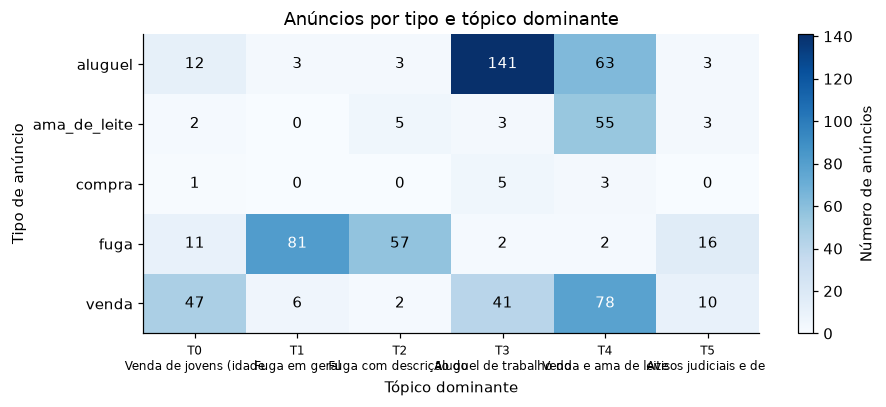

In [9]:
tt = pd.crosstab(base["c_tipo"], base["dominante"])
tt.columns = [f"T{t}" for t in tt.columns]
tt["Total"] = tt.sum(axis=1)
tt.loc["Total"] = tt.sum()
print(tt.to_string())

mat = pd.crosstab(base["c_tipo"], base["dominante"]).reindex(columns=range(K), fill_value=0)
fig, ax = plt.subplots(figsize=(8.5, 3.8))
im = ax.imshow(mat.values, cmap="Blues", aspect="auto")
ax.set_xticks(range(K)); ax.set_xticklabels([f"T{t}\n{NOMES[t][:22]}" for t in range(K)], fontsize=8)
ax.set_yticks(range(len(mat))); ax.set_yticklabels(mat.index)
for i in range(mat.shape[0]):
    for j in range(K):
        v = mat.values[i, j]
        ax.text(j, i, str(v), ha="center", va="center", color="white" if v > mat.values.max() * 0.5 else "black")
ax.set_title("Anúncios por tipo e tópico dominante"); ax.set_xlabel("Tópico dominante"); ax.set_ylabel("Tipo de anúncio")
fig.colorbar(im, ax=ax, label="Número de anúncios")
fig.tight_layout(); plt.show()

**O que se vê:** os tópicos **acompanham bastante o tipo**: 141 dos 225 aluguéis estão em T3, 81+57 dos 169 anúncios de fuga estão em T1 e T2, e 55 dos 68 de ama de leite em T4. Então, em boa medida, os tópicos **são os tipos** (o modelo não "descobriu" muito além do que a classificação já dizia). Há mistura que dá algo a mais: a venda se divide entre T4 (78), T0 (47) e T3 (41), e T5 reúne 16 anúncios tipados como fuga, mas que são avisos ou relatos de navegação. A vantagem dos tópicos está nas **palavras** (por exemplo, "serviço doméstico" atravessando aluguel e venda), não em separar tipos.

## 8. Comparação com o modelo `t2` (8 tópicos)
Para cada tópico de `t2`, buscamos o tópico de `t3` mais parecido pela **similaridade de cosseno** entre as distribuições de palavras.

> **Aproximação:** o banco guarda só as **12 palavras de maior peso** de cada tópico. Usamos a união dessas palavras
> como vocabulário e **peso 0** para as ausentes. O resultado é aproximado e ignora a cauda de cada tópico.

In [10]:
pal = palavras.pivot_table(index=["versao", "topico"], columns="palavra", values="peso", fill_value=0)
M2, M3 = pal.loc[COMPARA], pal.loc[MODELO]
vocab = sorted(set(M2.columns) | set(M3.columns))
A = M2.reindex(columns=vocab, fill_value=0).values
B = M3.reindex(columns=vocab, fill_value=0).values
cos = (A / np.linalg.norm(A, axis=1, keepdims=True)) @ (B / np.linalg.norm(B, axis=1, keepdims=True)).T
linhas = []
for i, t2 in enumerate(M2.index):
    j = int(cos[i].argmax())
    linhas.append({"Tópico t2": t2, "12 palavras de t2": ", ".join(palavras[(palavras.versao == COMPARA) & (palavras.topico == t2)]["palavra"].head(6)) + "…",
                   "Mais parecido em t3": f"T{M3.index[j]} {NOMES[M3.index[j]]}", "Cosseno": round(float(cos[i, j]), 2)})
pd.DataFrame(linhas).set_index("Tópico t2")

,12 palavras de t2,Mais parecido em t3,Cosseno
Tópico t2,,,
0,"anos, vende, nacao, moleque, idade, preta…",T0 Venda de jovens (idade e nação),0.95
1,"dia, nome, fugiu, corrente, escravo, bem…",T1 Fuga em geral,0.93
2,"alvicaras, nome, nacao, dia, fugiu, recebera…",T2 Fuga com descrição do corpo,0.98
3,"aluga, preta, preto, servico, lavar, vende…",T3 Aluguel de trabalho doméstico,0.95
4,"leite, ama, aluga, precisa, preta, boa…",T4 Venda e ama de leite,0.91
5,"escravo, vende, dito, preco, comprar, juiz…",T5 Avisos judiciais e de navegação,0.66
6,"dois, tendo, embarcacoes, fogo, escravos, tenente…",T5 Avisos judiciais e de navegação,0.30
7,"dias, vende, nem, rio, figura, anos…",T0 Venda de jovens (idade e nação),0.37


**O que se vê:** os 5 primeiros tópicos de `t2` têm par claro em `t3`, com cosseno entre 0,91 e 0,98 (T2 de `t2` com T2 de `t3`: 0,98). Os tópicos 5, 6 e 7 de `t2` não têm par bom: o 5 (escravo, vende, juiz, comprar) casa com o T5 de `t3` só com 0,66; o 6 (embarcações, fogo, tenente) com 0,30 e o 7 (dias, vende, nem, rio) com 0,37. Isso indica que, ao passar de 8 para 6 tópicos, os **temas estáveis foram mantidos** e só os tópicos de ruído mudaram. É uma comparação **aproximada** (só 12 palavras por tópico).

## 9. O que os resultados dizem e o que não dizem

**O que sustenta (com as ressalvas abaixo):**

- Os tópicos de **fuga caem** de antes de 1831 para 1871–1888: T2 de 25,8% para 6,5% e T1 de 23,8% para 12,2% (seção 4). **Mas** a fuga também cai de 57,8% para 18,1% dos anúncios do corpus, então o tópico pode só refletir isso.
- O tópico de **aluguel de trabalho doméstico cresce** período a período, de 7,7% para 38,6%, e passa de 18,4% (1831–1850) a 27,6% (1850–1871) e 38,6% (1871–1888) (seção 4).
- Os temas de **aluguel, fuga e ama de leite** reaparecem entre `t2` e `t3` (cosseno de 0,91 a 0,98) e nos exemplos lidos (seções 3 e 8).

**O que NÃO dizem:**

- **Não é amostra da população.** Os anúncios vêm de **frases de busca**; a queda da fuga e a subida do aluguel podem refletir **o que a busca achou** em cada período (a composição por tipo muda), não o que se anunciava de fato.
- **Corpus pequeno:** 655 anúncios (102, 134, 192 e 227 por período). O `aluguel_incerto` (67 anúncios) ficou **fora** do corpus.
- **Estabilidade moderada:** só 52% dos tópicos se repetem com k = 6. Tratar os números como pistas, não medidas.
- **Os tópicos seguem em grande parte os tipos** (seção 7), então "tópico por período" é em boa medida "tipo por período".
- **Há tópicos de ruído** (T5, avisos judiciais e de navegação) e o T0 mistura colunas de classificados.
- **Sexo e idade:** diferenças por sexo vêm do tipo (seção 5) e as de idade têm n de 9 a 58 (seção 6).
- **Os nomes são hipóteses do grupo**, escolhidas lendo palavras e exemplos, não fatos.